========== DATASET ==========
 Study_Hours  Attendance  Assignment_Marks  Marks
           1          50                10     35
           2          55                12     40
           3          60                15     45
           4          65                16     50
           5          70                18     55
           6          75                20     60
           7          80                22     65
           8          85                24     70
           9          90                26     80
          10          95                28     90

========== DATA SPLIT ==========
Training samples: 8
Testing samples: 2

========== SIMPLE LINEAR REGRESSION ==========
Intercept: 26.9828
Coefficient: 5.7759
R2 Score: 0.996
RMSE: 1.2684

Actual vs Predicted Marks (Simple Regression):
 Study_Hours  Actual_Marks  Predicted_Marks
           9            80            78.97
           2            40            38.53

========== MULTIPLE LINEAR REGRESSION ==========
I

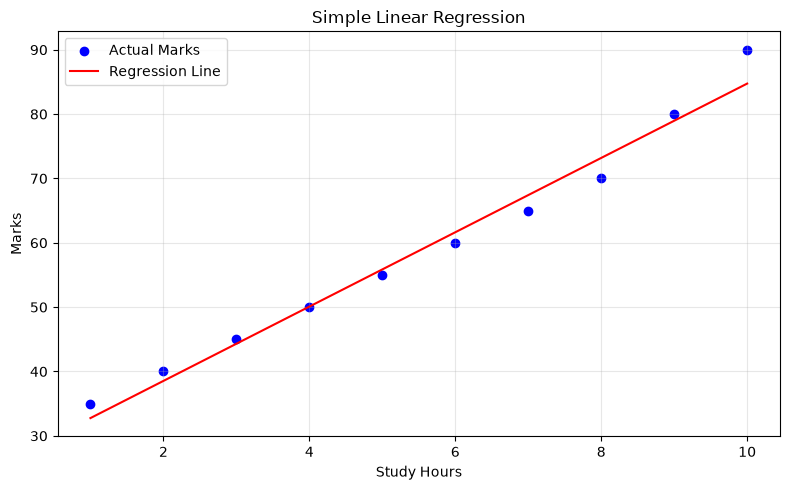

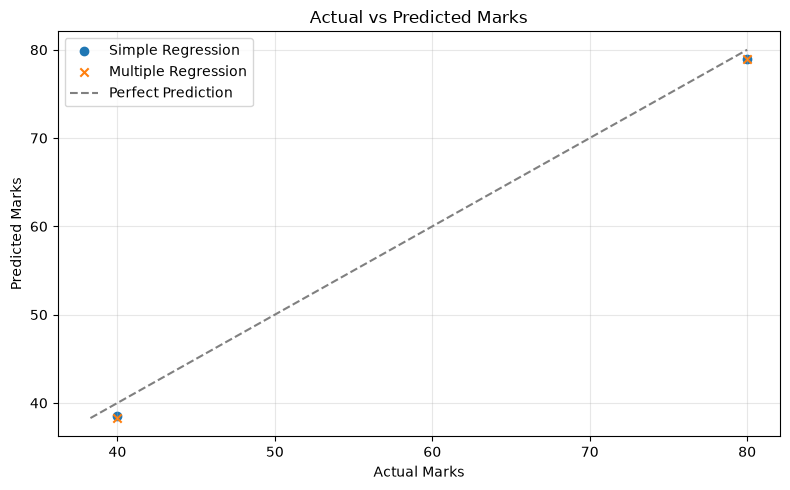


Program executed successfully!


In [1]:

# Simple and Multiple Linear Regression

# Step 1: Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Step 2: Create a sample dataset
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Attendance": [50, 55, 60, 65, 70, 75, 80, 85, 90, 95],
    "Assignment_Marks": [10, 12, 15, 16, 18, 20, 22, 24, 26, 28],
    "Marks": [35, 40, 45, 50, 55, 60, 65, 70, 80, 90]
}

df = pd.DataFrame(data)

print("========== DATASET ==========")
print(df.to_string(index=False))

# Step 3: Select input and output variables

# Simple Linear Regression: One input variable
X_simple = df[["Study_Hours"]]

# Multiple Linear Regression: Three input variables
X_multiple = df[
    ["Study_Hours", "Attendance", "Assignment_Marks"]
]

y = df["Marks"]

# Step 4: Split the dataset into training and testing sets
X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple,
    y,
    test_size=0.2,
    random_state=42
)

X_train_m, X_test_m, _, _ = train_test_split(
    X_multiple,
    y,
    test_size=0.2,
    random_state=42
)

print("\n========== DATA SPLIT ==========")
print("Training samples:", len(X_train_s))
print("Testing samples:", len(X_test_s))

# Step 5: Simple Linear Regression
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train)

simple_predictions = simple_model.predict(X_test_s)

simple_r2 = r2_score(y_test, simple_predictions)
simple_rmse = np.sqrt(
    mean_squared_error(y_test, simple_predictions)
)

print("\n========== SIMPLE LINEAR REGRESSION ==========")
print("Intercept:", round(simple_model.intercept_, 4))
print("Coefficient:", round(simple_model.coef_[0], 4))
print("R2 Score:", round(simple_r2, 4))
print("RMSE:", round(simple_rmse, 4))

print("\nActual vs Predicted Marks (Simple Regression):")
simple_results = pd.DataFrame({
    "Study_Hours": X_test_s["Study_Hours"].values,
    "Actual_Marks": y_test.values,
    "Predicted_Marks": simple_predictions.round(2)
})
print(simple_results.to_string(index=False))

# Step 6: Multiple Linear Regression
multiple_model = LinearRegression()
multiple_model.fit(X_train_m, y_train)

multiple_predictions = multiple_model.predict(X_test_m)

multiple_r2 = r2_score(y_test, multiple_predictions)
multiple_rmse = np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
)

print("\n========== MULTIPLE LINEAR REGRESSION ==========")
print("Intercept:", round(multiple_model.intercept_, 4))

print("Coefficients:")
for feature, coefficient in zip(
    X_multiple.columns, multiple_model.coef_
):
    print(f"{feature}: {coefficient:.4f}")

print("R2 Score:", round(multiple_r2, 4))
print("RMSE:", round(multiple_rmse, 4))

print("\nActual vs Predicted Marks (Multiple Regression):")
multiple_results = pd.DataFrame({
    "Actual_Marks": y_test.values,
    "Predicted_Marks": multiple_predictions.round(2)
})
print(multiple_results.to_string(index=False))

# Step 7: Predict marks for a new student

new_student_simple = pd.DataFrame({
    "Study_Hours": [6]
})

new_student_multiple = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [80],
    "Assignment_Marks": [22]
})

simple_new_prediction = simple_model.predict(
    new_student_simple
)[0]

multiple_new_prediction = multiple_model.predict(
    new_student_multiple
)[0]

print("\n========== NEW STUDENT PREDICTION ==========")
print(
    "Predicted marks using Simple Regression:",
    round(simple_new_prediction, 2)
)

print(
    "Predicted marks using Multiple Regression:",
    round(multiple_new_prediction, 2)
)

# Step 8: Plot Simple Linear Regression
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Study_Hours"],
    df["Marks"],
    color="blue",
    label="Actual Marks"
)

# Sort study hours so the regression line displays correctly
sorted_indices = np.argsort(df["Study_Hours"].values)
X_sorted = X_simple.iloc[sorted_indices]

plt.plot(
    X_sorted["Study_Hours"],
    simple_model.predict(X_sorted),
    color="red",
    label="Regression Line"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Step 9: Compare actual and predicted marks
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    simple_predictions,
    label="Simple Regression"
)

plt.scatter(
    y_test,
    multiple_predictions,
    label="Multiple Regression",
    marker="x"
)

# Reference line for perfect predictions
min_marks = min(y_test.min(), simple_predictions.min(),
                multiple_predictions.min())
max_marks = max(y_test.max(), simple_predictions.max(),
                multiple_predictions.max())

plt.plot(
    [min_marks, max_marks],
    [min_marks, max_marks],
    linestyle="--",
    color="gray",
    label="Perfect Prediction"
)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nProgram executed successfully!")
